# WTI seasonality: four-model backtest
Two return definitions × two predictor sets. P denotes the front-month price-change target; R denotes the CL2-to-CL1 return proxy. S denotes seasonality with volatility interactions; SM adds macroeconomic and positioning predictors.

| Model | Monthly target | Predictors |
|---|---|---|
| P_S | $r_t^P=\ln(CL1_t/CL1_{t-1})$ | Seasonal core | 
| P_SM | $r_t^P$ | Seasonal core + macro/positioning | 
| R_S | $r_t^R=\ln(CL1_t/CL2_{t-1})$ | Seasonal core | 
| R_SM | $r_t^R$ | Seasonal core + macro/positioning | 

For $k\in\{P,R\}$, coefficients are separately estimated:

$$r_t^k=\alpha_{k,S}+\gamma_{k,S}H_{t-1}+\delta_{k,S,s}S_t+\delta_{k,S,w}W_t+\theta_{k,S,s}S_tH_{t-1}+\theta_{k,S,w}W_tH_{t-1}+\varepsilon_{k,S,t}.$$

$$r_t^k=\alpha_{k,SM}+\beta_k'X_{t-1}+\gamma_{k,SM}H_{t-1}+\delta_{k,SM,s}S_t+\delta_{k,SM,w}W_t+\theta_{k,SM,s}S_tH_{t-1}+\theta_{k,SM,w}W_tH_{t-1}+\varepsilon_{k,SM,t}.$$

$S_t$: May–September; $W_t$: November–March; April/October are the reference. $H_{t-1}$ is the supplied lagged VIX state, above its expanding 70th percentile (36-month minimum history). VIX represents broad-market volatility. $X_{t-1}$ contains CPI YoY, change in 3M yield, industrial-production log growth and net-commercial-position percentage change, using the workbook's one-month lags. High-state seasonal effects equal $\delta+\theta$.

**Protocol:** initial estimation December 1997–December 2012; expanding monthly OLS forecasts January 2013–June 2024 (138 months, 24 high-state months). Same dates, indicators, estimation rules and costs for all four. Model specifications remain fixed; these are historical research results on previously reviewed data.

**Attribution:** S versus State tests the seasonal block; S versus Season tests interactions. SM versus MacroState tests the seasonal block conditional on macro inputs; SM versus MacroSeason tests interactions. SM versus S tests macro information. Benchmarks are refitted separately for each target. Compare forecast errors within targets; cross-target R² is relative to different historical-mean forecasts.

**Inputs:** put `model_ready_dataset.xlsx` and `Oil Data.xlsx` beside this notebook. The first supplies all predictors and the P target; only `Industry_M` prices in the second are used to compute R. Required packages: pandas, numpy, scipy, matplotlib, statsmodels, openpyxl.

**Return interpretation:** $r_t^R=r_t^P-\ln(CL2_{t-1}/CL1_{t-1})$. Their difference is the prior curve ratio, not an additional forecasting feature. R is a same-contract holding-return proxy only if contract identity and roll dates align. The workbook does not establish that mapping. Trading results below are unit-notional proxy simulations, not verified executable futures-account returns; release vintages and execution prices remain implementation assumptions.


**Findings:** Neither return definition produces an advantage over its historical-mean forecast. High-state OOS R² is −2.27% (P_S), −24.41% (P_SM), −1.90% (R_S) and −39.29% (R_SM). Within both targets, adding macro inputs worsens forecast accuracy. Seasonal terms modestly improve the macro-only baselines, but high-state CW p-values are 0.268 (P) and 0.293 (R); the corresponding bootstrap intervals include zero. At 10 bps, all four long/flat proxy strategies have negative CAGR. These results support a weak and unstable seasonal forecasting signal, rather than an implementable trading edge.

## P target: estimation

In [1]:
bundles={}
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.stats.diagnostic import acorr_breusch_godfrey,het_breuschpagan,het_arch,breaks_cusumolsresid
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns',16)
pd.set_option('display.float_format',lambda x:f'{x:.5f}')
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
DATA_PATH=Path('model_ready_dataset.xlsx')
d=pd.read_excel(DATA_PATH,parse_dates=['Date']).set_index('Date').sort_index().loc['1997-12-31':'2024-06-30']

raw=pd.read_excel(Path('Oil Data.xlsx'),sheet_name='Industry_M')
raw.columns=raw.columns.str.strip()
raw['Date']=pd.to_datetime(raw['Date']).dt.to_period('M').dt.to_timestamp('M')
raw=raw.sort_values('Date').set_index('Date')
assert raw.index.is_unique and (raw[['CL1','CL2']]>0).all().all()
raw['P']=np.log(raw.CL1/raw.CL1.shift(1))
raw['R']=np.log(raw.CL1/raw.CL2.shift(1))
np.testing.assert_allclose(d.ret_CL1,raw.P.reindex(d.index),atol=1e-10)
d['ret_R']=raw.R.reindex(d.index)
assert np.isfinite(d['ret_R']).all()
np.testing.assert_allclose(d.ret_R,d.ret_CL1-np.log(raw.CL2.shift(1)/raw.CL1.shift(1)).reindex(d.index),atol=1e-10)

Y='ret_CL1';H='L1_HighVol'
BASE=['L1_CPI_YoY','L1_d_3M_Yield','L1_d_IndProd','L1_d_NetCommercial']
CORE=[H,'Summer','Winter','Summer_x_HighVol','Winter_x_HighVol']
SPECS={'State':[H],'Season':[H,'Summer','Winter'],'P_S':CORE,'P_SM':BASE+CORE,'MacroState':BASE+[H],'MacroSeason':BASE+[H,'Summer','Winter']}
assert d.index.is_unique and np.isfinite(d[[Y]+BASE+CORE]).all().all()
assert (d.Summer==d.index.month.isin([5,6,7,8,9])).all()
assert (d.Winter==d.index.month.isin([11,12,1,2,3])).all()
assert (d.Summer_x_HighVol==d.Summer*d[H]).all()
assert (d.Winter_x_HighVol==d.Winter*d[H]).all()
def design(z,cols):return sm.add_constant(z[cols].astype(float),has_constant='add')
def forecast(frame,start='2013-01-31',window=None):
 rows=[];coefs=[]
 for date in frame.loc[start:].index:
  tr=frame.loc[frame.index<date].copy()
  if window:tr=tr.tail(window)
  row=frame.loc[[date]]
  rec={'Date':date,'Actual':row[Y].iloc[0],'High':row[H].iloc[0],'Mean':tr[Y].mean(),'Zero':0.0}
  for model,cols in SPECS.items():
   sample=tr.dropna(subset=[Y]+cols)
   fit=sm.OLS(sample[Y],design(sample,cols)).fit()
   rec[model]=float(fit.predict(design(row,cols)).iloc[0])
   if model in ['P_S','P_SM']:coefs.append({'Date':date,'Model':model,**fit.params.to_dict()})
  rows.append(rec)
 return pd.DataFrame(rows).set_index('Date'),pd.DataFrame(coefs)
p,coef=forecast(d)
assert len(p)==138
print('Evaluation months:',len(p),'High:',int(p.High.sum()),'Low:',int((p.High==0).sum()))


Evaluation months: 138 High: 24 Low: 114


## Forecast accuracy
RMSE and MAE are decimal log-return errors. Positive R² means lower MSE than the named benchmark. Direction is sign accuracy. All, High and Low use identical months for both models. State and Season are nested controls for attributing seasonal information.

,State,Model,N,MSE,RMSE,MAE,R2_mean,R2_S,Direction
0,All,Mean,138,0.01560,0.12491,0.08234,0.00000,0.02638,0.52174
1,All,Zero,138,0.01549,0.12446,0.08225,0.00715,0.03335,NaN
2,All,State,138,0.01577,0.12559,0.08266,-0.01083,0.01584,0.50000
3,All,Season,138,0.01592,0.12618,0.08276,-0.02040,0.00653,0.46377
4,All,P_S,138,0.01603,0.12659,0.08366,-0.02710,0.00000,0.48551
5,All,P_SM,138,0.01881,0.13715,0.09129,-0.20546,-0.17365,0.46377
6,All,MacroState,138,0.01905,0.13801,0.09097,-0.22079,-0.18858,0.46377
7,All,MacroSeason,138,0.01904,0.13800,0.09103,-0.22058,-0.18837,0.44928
8,High,Mean,24,0.05236,0.22882,0.14396,0.00000,0.02218,0.54167
9,High,Zero,24,0.05230,0.22869,0.14444,0.00108,0.02324,NaN


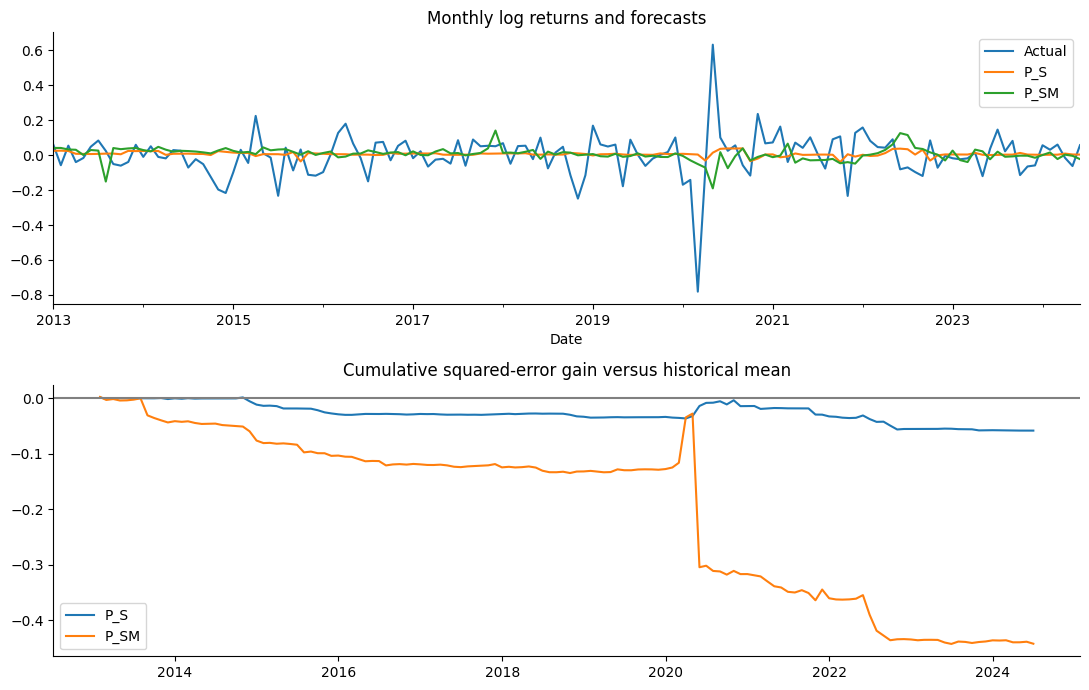

In [2]:
def evaluate(f):
 rows=[]
 for group,q in [('All',f),('High',f.loc[f.High==1]),('Low',f.loc[f.High==0])]:
  for model in ['Mean','Zero']+list(SPECS):
   err=q.Actual-q[model];mse=(err**2).mean()
   rows.append([group,model,len(q),mse,np.sqrt(mse),abs(err).mean(),1-mse/((q.Actual-q.Mean)**2).mean(),1-mse/((q.Actual-q.P_S)**2).mean(),(np.sign(q.Actual)==np.sign(q[model])).mean() if model!='Zero' else np.nan])
 return pd.DataFrame(rows,columns=['State','Model','N','MSE','RMSE','MAE','R2_mean','R2_S','Direction'])
accuracy=evaluate(p);display(accuracy)
fig,ax=plt.subplots(2,1,figsize=(11,7))
p[['Actual','P_S','P_SM']].plot(ax=ax[0]);ax[0].set_title('Monthly log returns and forecasts')
for model in ['P_S','P_SM']:
 gain=(p.Actual-p.Mean)**2-(p.Actual-p[model])**2
 ax[1].plot(gain.cumsum(),label=model)
ax[1].axhline(0,color='grey');ax[1].legend();ax[1].set_title('Cumulative squared-error gain versus historical mean')
plt.tight_layout();plt.show()


## Incremental predictive value
Nested comparisons test seasonality (P_S vs State), interactions (P_S vs Season), and macro information (P_SM vs P_S), as well as both models against the mean. Positive raw MSE gains favour the larger model. Clark–West p-values are one-sided HAC approximations; non-high months remain zero-weighted on the full calendar. Six-month circular block bootstrap intervals use 1,999 draws and condition on the realised forecast sequence.

In [3]:
rng=np.random.default_rng(20261114);N=len(p)
idx=(rng.integers(0,N,(1999,int(np.ceil(N/6))))[:,:,None]+np.arange(6))%N;idx=idx.reshape(1999,-1)[:,:N]
rows=[]
for big,small in [('P_S','Mean'),('P_SM','Mean'),('P_S','State'),('P_S','Season'),('P_SM','P_S'),('P_SM','MacroState'),('P_SM','MacroSeason')]:
 raw=((p.Actual-p[small])**2-(p.Actual-p[big])**2).to_numpy()
 adjusted=raw+(p[small]-p[big]).to_numpy()**2
 for group,mask in [('All',np.ones(N)),('High',p.High.to_numpy())]:
  den=mask[idx].sum(1);boot=(raw[idx]*mask[idx]).sum(1)/np.where(den>0,den,np.nan)
  lo,hi=np.nanquantile(boot,[.025,.975])
  for lag in [3,6]:
   f=sm.OLS(mask*adjusted,np.ones((N,1))).fit(cov_type='HAC',cov_kwds={'maxlags':lag})
   rows.append([big,small,group,lag,np.sum(mask*raw)/mask.sum(),stats.norm.sf(f.tvalues[0]),lo,hi])
tests=pd.DataFrame(rows,columns=['Model','Benchmark','State','HAC','MSE_gain','CW_p','CI_low','CI_high'])
display(tests.query('HAC==3'))


,Model,Benchmark,State,HAC,MSE_gain,CW_p,CI_low,CI_high
0,P_S,Mean,All,3,-0.00042,0.82903,-0.00096,0.00015
2,P_S,Mean,High,3,-0.00119,0.62243,-0.00415,0.00193
4,P_SM,Mean,All,3,-0.00321,0.88941,-0.00689,-0.00058
6,P_SM,Mean,High,3,-0.01278,0.85017,-0.02845,0.00302
8,P_S,State,All,3,-0.00025,0.62544,-0.00082,0.00045
10,P_S,State,High,3,-0.00064,0.48603,-0.00398,0.00320
12,P_S,Season,All,3,-0.00010,0.49249,-0.00055,0.00045
14,P_S,Season,High,3,-0.00050,0.52322,-0.00313,0.00256
16,P_SM,P_S,All,3,-0.00278,0.82618,-0.00694,0.00001
18,P_SM,P_S,High,3,-0.01159,0.80411,-0.03002,0.00552


## Trading outcomes
Main rule: long when the forecast is positive, otherwise flat; unit notional exposure; zero cash yield; 10 bps per unit position change. Both models also use identical long/short rules, costs of 0/5/25 bps and high-state-only trading. Initial entry and terminal liquidation are charged. Drawdown includes starting wealth of one; all annualised metrics retain the full calendar. Returns use this panel’s target as a unit-notional proxy. The 2024 annual row covers January–June.

,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover
0,P_S,-0.09177,0.40902,-0.03876,-0.87679,0.89855,22.00000
1,P_SM,-0.04048,0.22580,-0.06924,-0.71711,0.64493,42.00000
2,Mean,-0.06361,0.35103,0.01051,-0.82516,0.99275,4.00000
3,AlwaysLong,-0.01043,0.43716,0.18463,-0.82499,1.00000,2.00000


,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover,Rule,Cost_bps,High_only
0,P_S,-0.09008,0.40927,-0.03406,-0.87592,0.89855,22.00000,long_flat,0,False
1,P_SM,-0.03700,0.22601,-0.05302,-0.71598,0.64493,42.00000,long_flat,0,False
8,P_S,-0.09092,0.40915,-0.03641,-0.87636,0.89855,22.00000,long_flat,5,False
9,P_SM,-0.03874,0.22590,-0.06113,-0.71654,0.64493,42.00000,long_flat,5,False
16,P_S,-0.09177,0.40902,-0.03876,-0.87679,0.89855,22.00000,long_flat,10,False
17,P_SM,-0.04048,0.22580,-0.06924,-0.71711,0.64493,42.00000,long_flat,10,False
20,P_S,-0.02579,0.31492,0.06062,-0.58288,0.07971,10.00000,long_flat,10,True
21,P_SM,0.00584,0.09913,0.10648,-0.23821,0.10145,16.00000,long_flat,10,True
24,P_S,-0.09431,0.40867,-0.04581,-0.87809,0.89855,22.00000,long_flat,25,False
25,P_SM,-0.04568,0.22552,-0.09362,-0.71880,0.64493,42.00000,long_flat,25,False


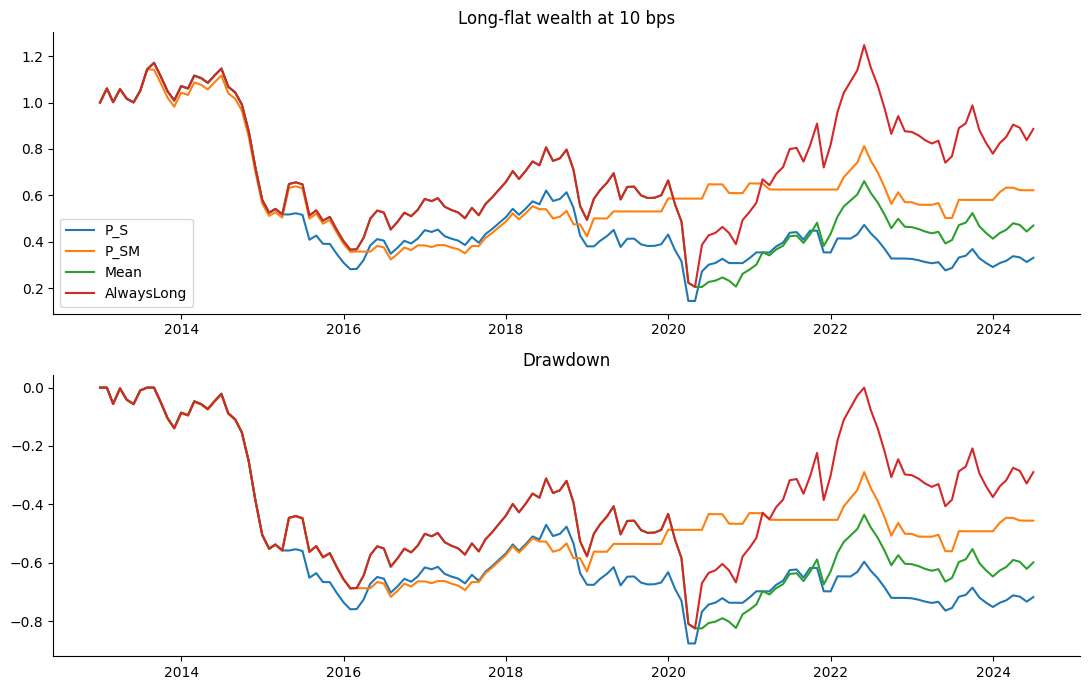

,P_S,P_SM,Mean,AlwaysLong
Date,,,,
2013,0.07087,0.04266,0.07087,0.07087
2014,-0.45875,-0.45875,-0.45875,-0.45875
2015,-0.46503,-0.30467,-0.30467,-0.30467
2016,0.45032,-0.02185,0.45032,0.45032
2017,0.12472,0.26894,0.12472,0.12472
2018,-0.24843,-0.13229,-0.24843,-0.24843
2019,0.13295,0.38767,0.34464,0.34464
2020,-0.23640,0.11112,-0.57897,-0.20537
2021,0.07492,-0.04097,0.55008,0.55008


In [4]:
def trade(f,rule='long_flat',cost=10,high_only=False):
 returns={};rows=[]
 for name in ['P_S','P_SM','Mean','AlwaysLong']:
  w=pd.Series(1.,index=f.index) if name=='AlwaysLong' else ((f[name]>0).astype(float) if rule=='long_flat' else np.sign(f[name]))
  if high_only:w=w*f.High
  turnover=w.diff().abs();turnover.iloc[0]=abs(w.iloc[0]);turnover.iloc[-1]+=abs(w.iloc[-1])
  r=w*np.expm1(f.Actual)-cost/10000*turnover
  assert (r>-1).all()
  wealth=(1+r).cumprod();peak=np.maximum.accumulate(np.r_[1,wealth])[1:];vol=r.std()*np.sqrt(12)
  rows.append([name,wealth.iloc[-1]**(12/len(r))-1,vol,r.mean()*12/vol if vol else np.nan,(wealth/peak-1).min(),abs(w).mean(),turnover.sum()]);returns[name]=r
 return pd.DataFrame(rows,columns=['Model','CAGR','Volatility','Sharpe','MaxDD','Exposure','Turnover']),pd.DataFrame(returns)
rows=[]
for rule in ['long_flat','long_short']:
 for cost in [0,5,10,25]:
  for high in [False,True]:
   tab,_=trade(p,rule,cost,high);rows.append(tab.assign(Rule=rule,Cost_bps=cost,High_only=high))
trading=pd.concat(rows,ignore_index=True)
main,net=trade(p);display(main)
display(trading.query("Model in ['P_S','P_SM'] and (Cost_bps==10 or (Rule=='long_flat' and High_only==False))"))
fig,ax=plt.subplots(2,1,figsize=(11,7))
for model in net:
 wealth=pd.concat([pd.Series([1.],index=[pd.Timestamp('2012-12-31')]),(1+net[model]).cumprod()])
 ax[0].plot(wealth,label=model);ax[1].plot(wealth/wealth.cummax()-1,label=model)
ax[0].legend();ax[0].set_title('Long-flat wealth at 10 bps');ax[1].set_title('Drawdown')
plt.tight_layout();plt.show()
display((1+net).groupby(net.index.year).prod()-1)


## Robustness under common changes
Both specifications are re-estimated under each scenario. Rolling120 uses the latest 120 months. ExtraLag delays P_SM's CPI, production and positioning inputs by one further month; P_S has no such inputs and provides an unchanged control. COVID exclusion affects scoring only. EarlierStart begins in 2011 and overlaps prior model development. These sensitivities are reported together, without selecting the best-performing variant.

In [5]:
rolling,_=forecast(d,window=120)
delay=d.copy();cols=['L1_CPI_YoY','L1_d_IndProd','L1_d_NetCommercial'];delay[cols]=delay[cols].shift(1)
lagged,_=forecast(delay)
early,_=forecast(d,start='2011-01-31')
mask=~p.index.to_period('M').isin(pd.period_range('2020-03','2020-06',freq='M'))
scenarios={'Main':p,'Rolling120':rolling,'ExtraLag':lagged,'ExcludeCOVID_score':p.loc[mask],'EarlierStart':early}
robust=pd.concat([evaluate(f).assign(Scenario=s) for s,f in scenarios.items()],ignore_index=True)
display(robust.query("Model in ['P_S','P_SM'] and State in ['All','High']")[['Scenario','State','Model','N','RMSE','MAE','R2_mean']])
np.testing.assert_allclose(lagged.P_S,p.P_S)


,Scenario,State,Model,N,RMSE,MAE,R2_mean
4,Main,All,P_S,138,0.12659,0.08366,-0.02710
5,Main,All,P_SM,138,0.13715,0.09129,-0.20546
12,Main,High,P_S,24,0.23140,0.14890,-0.02268
13,Main,High,P_SM,24,0.25522,0.16570,-0.24407
28,Rolling120,All,P_S,138,0.13623,0.08875,-0.18148
29,Rolling120,All,P_SM,138,0.15222,0.10435,-0.47503
36,Rolling120,High,P_S,24,0.26038,0.17250,-0.28246
37,Rolling120,High,P_SM,24,0.28308,0.20257,-0.51580
52,ExtraLag,All,P_S,138,0.12659,0.08366,-0.02710
53,ExtraLag,All,P_SM,138,0.12734,0.08600,-0.03926


## Statistical diagnostics
Common continuous inputs are assessed on the initial training sample ending in 2012. ADF tests a unit root; KPSS tests stationarity, with reported p-values bounded by its reference table. Residual diagnostics and joint seasonal restrictions are reported equally for P_S and P_SM. HAC(3)/(6) adjusts inference for dependence and heteroskedasticity. Coefficient paths describe stability during sequential estimation.

,Variable,ADF_p,KPSS_p_bound
0,ret_CL1,0.00001,0.10000
1,L1_CPI_YoY,0.20509,0.10000
2,L1_d_3M_Yield,0.11383,0.10000
3,L1_d_IndProd,0.01830,0.10000
4,L1_d_NetCommercial,0.00000,0.10000


,Model,Coefficient,HAC_SE,p
const,P_S,0.00804,0.01597,0.61467
L1_HighVol,P_S,-0.04370,0.04429,0.32374
Summer,P_S,-0.00084,0.02047,0.96717
Winter,P_S,0.01716,0.01883,0.36231
Summer_x_HighVol,P_S,0.05489,0.05281,0.29865
Winter_x_HighVol,P_S,0.01711,0.04095,0.67615
const,P_SM,0.04252,0.02147,0.04765
L1_CPI_YoY,P_SM,-0.01494,0.00634,0.01846
L1_d_3M_Yield,P_SM,0.05343,0.02707,0.04839
L1_d_IndProd,P_SM,2.54606,1.30355,0.05080


Model,P_S,P_SM
Test,,
ARCH3,0.10635,0.45326
BG12,0.04251,0.06255
BG3,0.45786,0.52030
BP,0.00292,0.00884
CUSUM,0.75186,0.42440


,Model,HAC,Hypothesis,p
0,P_S,3,Interactions,0.49750
1,P_S,3,High-state seasonal effects,0.52177
2,P_S,6,Interactions,0.42511
3,P_S,6,High-state seasonal effects,0.47488
4,P_SM,3,Interactions,0.90450
5,P_SM,3,High-state seasonal effects,0.86721
6,P_SM,6,Interactions,0.87335
7,P_SM,6,High-state seasonal effects,0.86227


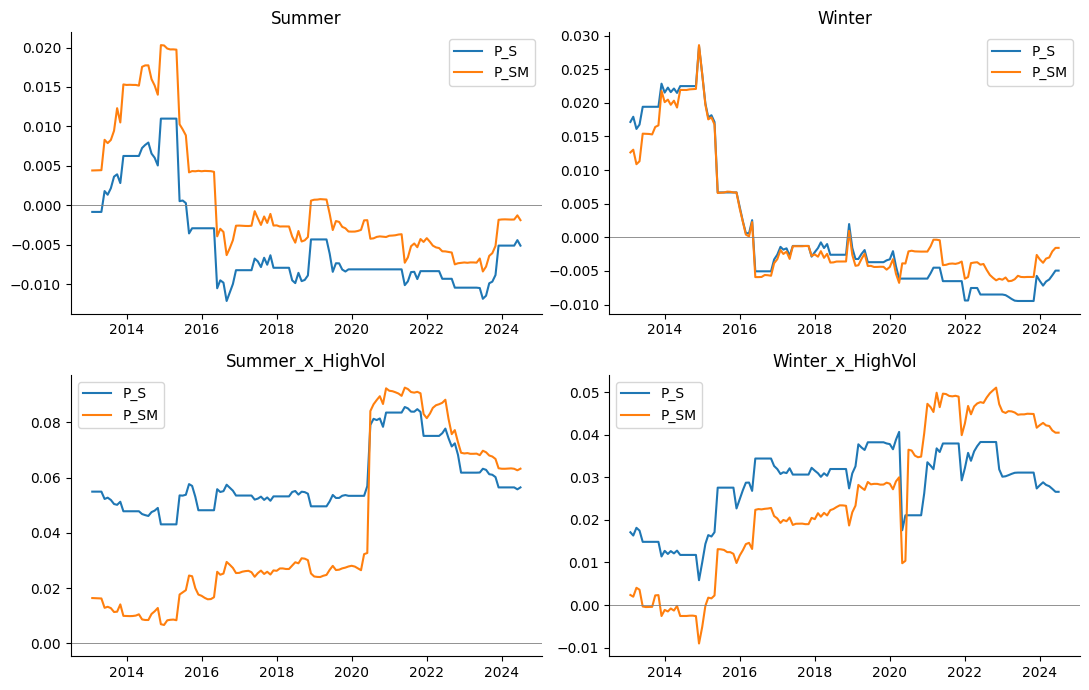

In [6]:
train=d.loc[:'2012-12-31'];stationarity=[]
for col in [Y]+BASE:
 with warnings.catch_warnings():
  warnings.simplefilter('ignore');ad=adfuller(train[col],autolag='AIC');kp=kpss(train[col],regression='c',nlags='auto')
 stationarity.append([col,ad[1],kp[1]])
display(pd.DataFrame(stationarity,columns=['Variable','ADF_p','KPSS_p_bound']))
diag=[];wald=[];coef_tables=[]
for model in ['P_S','P_SM']:
 x=design(train,SPECS[model]);fit=sm.OLS(train[Y],x).fit()
 values={'BG3':acorr_breusch_godfrey(fit,nlags=3)[1],'BG12':acorr_breusch_godfrey(fit,nlags=12)[1],'BP':het_breuschpagan(fit.resid,x)[1],'ARCH3':het_arch(fit.resid,nlags=3)[1],'CUSUM':breaks_cusumolsresid(fit.resid,ddof=x.shape[1])[1]}
 for name,val in values.items():diag.append([model,name,val])
 for lag in [3,6]:
  f=sm.OLS(train[Y],x).fit(cov_type='HAC',cov_kwds={'maxlags':lag})
  if lag==3:coef_tables.append(pd.DataFrame({'Model':model,'Coefficient':f.params,'HAC_SE':f.bse,'p':f.pvalues}))
  for label,r in [('Interactions','Summer_x_HighVol=0, Winter_x_HighVol=0'),('High-state seasonal effects','Summer+Summer_x_HighVol=0, Winter+Winter_x_HighVol=0')]:
   w=f.wald_test(r,scalar=True);wald.append([model,lag,label,float(w.pvalue)])
diagnostics=pd.DataFrame(diag,columns=['Model','Test','p']);season_tests=pd.DataFrame(wald,columns=['Model','HAC','Hypothesis','p'])
display(pd.concat(coef_tables));display(diagnostics.pivot(index='Test',columns='Model',values='p'));display(season_tests)
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,term in zip(axes.flat,['Summer','Winter','Summer_x_HighVol','Winter_x_HighVol']):
 for model in ['P_S','P_SM']:
  z=coef.loc[coef.Model==model];ax.plot(z.Date,z[term],label=model)
 ax.axhline(0,color='grey',lw=.6);ax.set_title(term);ax.legend()
plt.tight_layout();plt.show()


## Trading assessment
The following summary uses the same sample, target, state and position rule for both models. Forecast skill relative to the mean and the incremental P_SM-versus-P_S test determine whether complexity adds information. Trading returns describe the economic consequences under the stated assumptions; 2024 annual returns cover only January–June.

In [7]:
summary=accuracy.query("Model in ['P_S','P_SM']")[['State','Model','RMSE','MAE','R2_mean','Direction']]
display(summary);display(main.query("Model in ['P_S','P_SM']"))

bundles['P']={key:globals()[key].copy() for key in ['accuracy','tests','trading','robust','diagnostics','season_tests','coef','p','main']}


,State,Model,RMSE,MAE,R2_mean,Direction
4,All,P_S,0.12659,0.08366,-0.02710,0.48551
5,All,P_SM,0.13715,0.09129,-0.20546,0.46377
12,High,P_S,0.23140,0.14890,-0.02268,0.37500
13,High,P_SM,0.25522,0.16570,-0.24407,0.41667
20,Low,P_S,0.09015,0.06992,-0.03329,0.50877
21,Low,P_SM,0.09516,0.07562,-0.15136,0.47368


,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover
0,P_S,-0.09177,0.40902,-0.03876,-0.87679,0.89855,22.00000
1,P_SM,-0.04048,0.22580,-0.06924,-0.71711,0.64493,42.00000


## R target: estimation

In [8]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.stats.diagnostic import acorr_breusch_godfrey,het_breuschpagan,het_arch,breaks_cusumolsresid
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns',16)
pd.set_option('display.float_format',lambda x:f'{x:.5f}')
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
DATA_PATH=Path('model_ready_dataset.xlsx')
d=pd.read_excel(DATA_PATH,parse_dates=['Date']).set_index('Date').sort_index().loc['1997-12-31':'2024-06-30']

raw=pd.read_excel(Path('Oil Data.xlsx'),sheet_name='Industry_M')
raw.columns=raw.columns.str.strip()
raw['Date']=pd.to_datetime(raw['Date']).dt.to_period('M').dt.to_timestamp('M')
raw=raw.sort_values('Date').set_index('Date')
assert raw.index.is_unique and (raw[['CL1','CL2']]>0).all().all()
raw['P']=np.log(raw.CL1/raw.CL1.shift(1))
raw['R']=np.log(raw.CL1/raw.CL2.shift(1))
np.testing.assert_allclose(d.ret_CL1,raw.P.reindex(d.index),atol=1e-10)
d['ret_R']=raw.R.reindex(d.index)
assert np.isfinite(d['ret_R']).all()
np.testing.assert_allclose(d.ret_R,d.ret_CL1-np.log(raw.CL2.shift(1)/raw.CL1.shift(1)).reindex(d.index),atol=1e-10)

Y='ret_R';H='L1_HighVol'
BASE=['L1_CPI_YoY','L1_d_3M_Yield','L1_d_IndProd','L1_d_NetCommercial']
CORE=[H,'Summer','Winter','Summer_x_HighVol','Winter_x_HighVol']
SPECS={'State':[H],'Season':[H,'Summer','Winter'],'R_S':CORE,'R_SM':BASE+CORE,'MacroState':BASE+[H],'MacroSeason':BASE+[H,'Summer','Winter']}
assert d.index.is_unique and np.isfinite(d[[Y]+BASE+CORE]).all().all()
assert (d.Summer==d.index.month.isin([5,6,7,8,9])).all()
assert (d.Winter==d.index.month.isin([11,12,1,2,3])).all()
assert (d.Summer_x_HighVol==d.Summer*d[H]).all()
assert (d.Winter_x_HighVol==d.Winter*d[H]).all()
def design(z,cols):return sm.add_constant(z[cols].astype(float),has_constant='add')
def forecast(frame,start='2013-01-31',window=None):
 rows=[];coefs=[]
 for date in frame.loc[start:].index:
  tr=frame.loc[frame.index<date].copy()
  if window:tr=tr.tail(window)
  row=frame.loc[[date]]
  rec={'Date':date,'Actual':row[Y].iloc[0],'High':row[H].iloc[0],'Mean':tr[Y].mean(),'Zero':0.0}
  for model,cols in SPECS.items():
   sample=tr.dropna(subset=[Y]+cols)
   fit=sm.OLS(sample[Y],design(sample,cols)).fit()
   rec[model]=float(fit.predict(design(row,cols)).iloc[0])
   if model in ['R_S','R_SM']:coefs.append({'Date':date,'Model':model,**fit.params.to_dict()})
  rows.append(rec)
 return pd.DataFrame(rows).set_index('Date'),pd.DataFrame(coefs)
p,coef=forecast(d)
assert len(p)==138
print('Evaluation months:',len(p),'High:',int(p.High.sum()),'Low:',int((p.High==0).sum()))


Evaluation months: 138 High: 24 Low: 114


## Forecast accuracy
RMSE and MAE are decimal log-return errors. Positive R² means lower MSE than the named benchmark. Direction is sign accuracy. All, High and Low use identical months for both models. State and Season are nested controls for attributing seasonal information.

,State,Model,N,MSE,RMSE,MAE,R2_mean,R2_S,Direction
0,All,Mean,138,0.01464,0.12101,0.08227,0.00000,0.02367,0.39855
1,All,Zero,138,0.01455,0.12062,0.08180,0.00630,0.02982,NaN
2,All,State,138,0.01482,0.12174,0.08277,-0.01220,0.01176,0.47826
3,All,Season,138,0.01492,0.12215,0.08289,-0.01908,0.00505,0.48551
4,All,R_S,138,0.01500,0.12246,0.08341,-0.02425,0.00000,0.46377
5,All,R_SM,138,0.01871,0.13680,0.08990,-0.27813,-0.24787,0.42754
6,All,MacroState,138,0.01886,0.13733,0.08950,-0.28806,-0.25756,0.44928
7,All,MacroSeason,138,0.01884,0.13725,0.08968,-0.28659,-0.25613,0.42754
8,High,Mean,24,0.04840,0.21999,0.14592,0.00000,0.01866,0.41667
9,High,Zero,24,0.04823,0.21962,0.14546,0.00338,0.02197,NaN


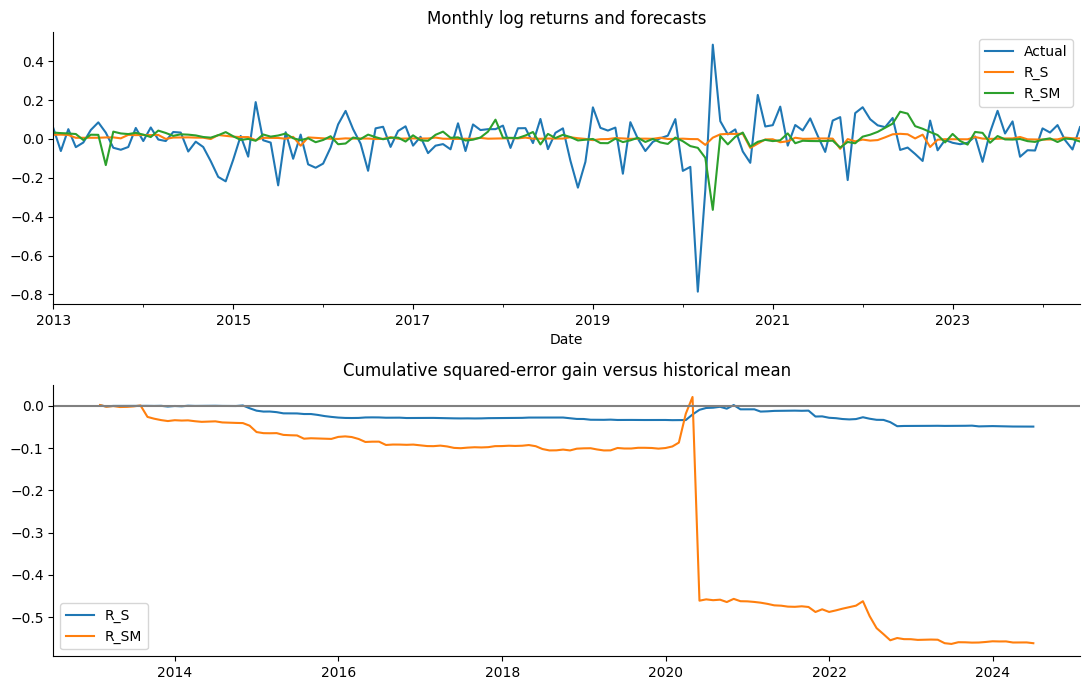

In [9]:
def evaluate(f):
 rows=[]
 for group,q in [('All',f),('High',f.loc[f.High==1]),('Low',f.loc[f.High==0])]:
  for model in ['Mean','Zero']+list(SPECS):
   err=q.Actual-q[model];mse=(err**2).mean()
   rows.append([group,model,len(q),mse,np.sqrt(mse),abs(err).mean(),1-mse/((q.Actual-q.Mean)**2).mean(),1-mse/((q.Actual-q.R_S)**2).mean(),(np.sign(q.Actual)==np.sign(q[model])).mean() if model!='Zero' else np.nan])
 return pd.DataFrame(rows,columns=['State','Model','N','MSE','RMSE','MAE','R2_mean','R2_S','Direction'])
accuracy=evaluate(p);display(accuracy)
fig,ax=plt.subplots(2,1,figsize=(11,7))
p[['Actual','R_S','R_SM']].plot(ax=ax[0]);ax[0].set_title('Monthly log returns and forecasts')
for model in ['R_S','R_SM']:
 gain=(p.Actual-p.Mean)**2-(p.Actual-p[model])**2
 ax[1].plot(gain.cumsum(),label=model)
ax[1].axhline(0,color='grey');ax[1].legend();ax[1].set_title('Cumulative squared-error gain versus historical mean')
plt.tight_layout();plt.show()


## Incremental predictive value
Nested comparisons test seasonality (R_S vs State), interactions (R_S vs Season), and macro information (R_SM vs R_S), as well as both models against the mean. Positive raw MSE gains favour the larger model. Clark–West p-values are one-sided HAC approximations; non-high months remain zero-weighted on the full calendar. Six-month circular block bootstrap intervals use 1,999 draws and condition on the realised forecast sequence.

In [10]:
rng=np.random.default_rng(20261114);N=len(p)
idx=(rng.integers(0,N,(1999,int(np.ceil(N/6))))[:,:,None]+np.arange(6))%N;idx=idx.reshape(1999,-1)[:,:N]
rows=[]
for big,small in [('R_S','Mean'),('R_SM','Mean'),('R_S','State'),('R_S','Season'),('R_SM','R_S'),('R_SM','MacroState'),('R_SM','MacroSeason')]:
 raw=((p.Actual-p[small])**2-(p.Actual-p[big])**2).to_numpy()
 adjusted=raw+(p[small]-p[big]).to_numpy()**2
 for group,mask in [('All',np.ones(N)),('High',p.High.to_numpy())]:
  den=mask[idx].sum(1);boot=(raw[idx]*mask[idx]).sum(1)/np.where(den>0,den,np.nan)
  lo,hi=np.nanquantile(boot,[.025,.975])
  for lag in [3,6]:
   f=sm.OLS(mask*adjusted,np.ones((N,1))).fit(cov_type='HAC',cov_kwds={'maxlags':lag})
   rows.append([big,small,group,lag,np.sum(mask*raw)/mask.sum(),stats.norm.sf(f.tvalues[0]),lo,hi])
tests=pd.DataFrame(rows,columns=['Model','Benchmark','State','HAC','MSE_gain','CW_p','CI_low','CI_high'])
display(tests.query('HAC==3'))


,Model,Benchmark,State,HAC,MSE_gain,CW_p,CI_low,CI_high
0,R_S,Mean,All,3,-0.00036,0.78583,-0.00090,0.00024
2,R_S,Mean,High,3,-0.00092,0.58056,-0.00429,0.00231
4,R_SM,Mean,All,3,-0.00407,0.84418,-0.01058,-0.00013
6,R_SM,Mean,High,3,-0.01901,0.81582,-0.04788,0.00437
8,R_S,State,All,3,-0.00018,0.56887,-0.00070,0.00050
10,R_S,State,High,3,-0.00038,0.44741,-0.00389,0.00304
12,R_S,Season,All,3,-0.00008,0.48237,-0.00047,0.00040
14,R_S,Season,High,3,-0.00033,0.50266,-0.00292,0.00210
16,R_SM,R_S,All,3,-0.00372,0.80050,-0.01059,0.00038
18,R_SM,R_S,High,3,-0.01809,0.78903,-0.04941,0.00646


## Trading outcomes
Main rule: long when the forecast is positive, otherwise flat; unit notional exposure; zero cash yield; 10 bps per unit position change. Both models also use identical long/short rules, costs of 0/5/25 bps and high-state-only trading. Initial entry and terminal liquidation are charged. Drawdown includes starting wealth of one; all annualised metrics retain the full calendar. Returns use this panel’s target as a unit-notional proxy. The 2024 annual row covers January–June.

,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover
0,R_S,-0.06503,0.30429,-0.08073,-0.82686,0.74638,26.00000
1,R_SM,-0.06100,0.20258,-0.20609,-0.79399,0.56522,54.00000
2,Mean,-0.12975,0.22958,-0.48245,-0.86558,0.59420,14.00000
3,AlwaysLong,-0.05842,0.39700,0.05638,-0.91152,1.00000,2.00000


,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover,Rule,Cost_bps,High_only
0,R_S,-0.06296,0.30458,-0.07323,-0.82424,0.74638,26.00000,long_flat,0,False
1,R_SM,-0.05659,0.20274,-0.18277,-0.79013,0.56522,54.00000,long_flat,0,False
8,R_S,-0.06399,0.30443,-0.07697,-0.82556,0.74638,26.00000,long_flat,5,False
9,R_SM,-0.05880,0.20266,-0.19442,-0.79207,0.56522,54.00000,long_flat,5,False
16,R_S,-0.06503,0.30429,-0.08073,-0.82686,0.74638,26.00000,long_flat,10,False
17,R_SM,-0.06100,0.20258,-0.20609,-0.79399,0.56522,54.00000,long_flat,10,False
20,R_S,0.03254,0.19665,0.23651,-0.19540,0.07246,8.00000,long_flat,10,True
21,R_SM,0.00233,0.08626,0.06937,-0.19460,0.09420,14.00000,long_flat,10,True
24,R_S,-0.06812,0.30387,-0.09200,-0.83073,0.74638,26.00000,long_flat,25,False
25,R_SM,-0.06760,0.20238,-0.24110,-0.79964,0.56522,54.00000,long_flat,25,False


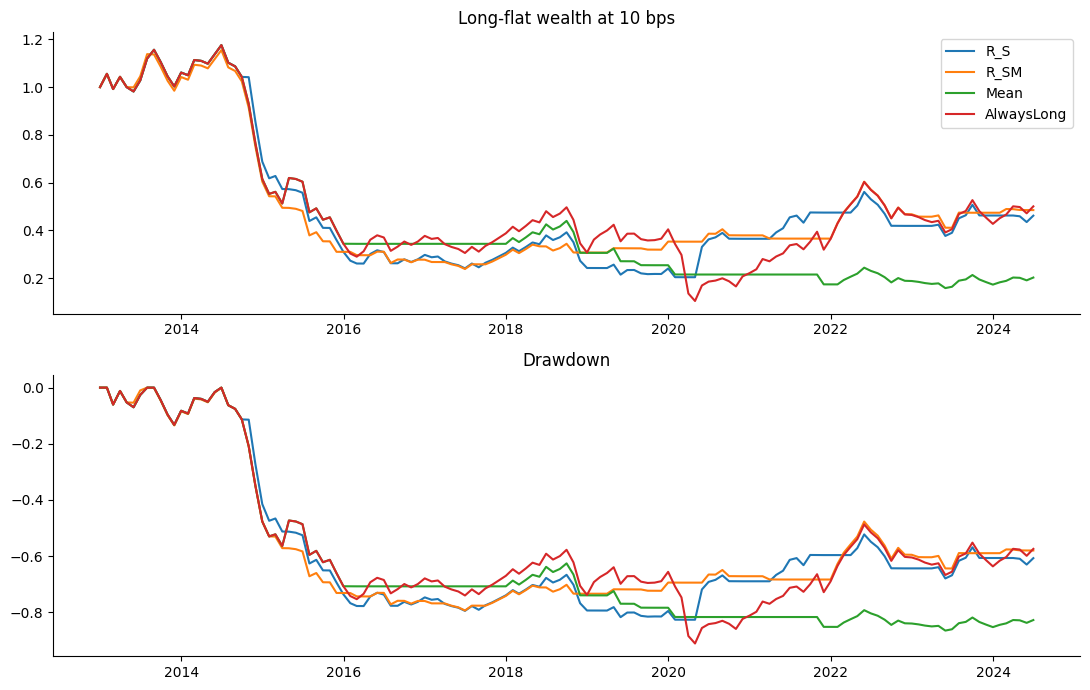

,R_S,R_SM,Mean,AlwaysLong
Date,,,,
2013,0.06107,0.04219,0.06107,0.06107
2014,-0.35159,-0.42019,-0.42019,-0.42019
2015,-0.54967,-0.48737,-0.44114,-0.44114
2016,-0.04051,-0.10576,-0.00100,0.09597
2017,0.02862,0.07556,0.00000,0.02862
2018,-0.20778,0.03027,-0.11041,-0.20778
2019,-0.00845,0.14978,-0.16925,0.31638
2020,0.51801,0.07367,-0.15340,-0.45396
2021,0.30100,-0.03577,-0.19256,0.65075


In [11]:
def trade(f,rule='long_flat',cost=10,high_only=False):
 returns={};rows=[]
 for name in ['R_S','R_SM','Mean','AlwaysLong']:
  w=pd.Series(1.,index=f.index) if name=='AlwaysLong' else ((f[name]>0).astype(float) if rule=='long_flat' else np.sign(f[name]))
  if high_only:w=w*f.High
  turnover=w.diff().abs();turnover.iloc[0]=abs(w.iloc[0]);turnover.iloc[-1]+=abs(w.iloc[-1])
  r=w*np.expm1(f.Actual)-cost/10000*turnover
  assert (r>-1).all()
  wealth=(1+r).cumprod();peak=np.maximum.accumulate(np.r_[1,wealth])[1:];vol=r.std()*np.sqrt(12)
  rows.append([name,wealth.iloc[-1]**(12/len(r))-1,vol,r.mean()*12/vol if vol else np.nan,(wealth/peak-1).min(),abs(w).mean(),turnover.sum()]);returns[name]=r
 return pd.DataFrame(rows,columns=['Model','CAGR','Volatility','Sharpe','MaxDD','Exposure','Turnover']),pd.DataFrame(returns)
rows=[]
for rule in ['long_flat','long_short']:
 for cost in [0,5,10,25]:
  for high in [False,True]:
   tab,_=trade(p,rule,cost,high);rows.append(tab.assign(Rule=rule,Cost_bps=cost,High_only=high))
trading=pd.concat(rows,ignore_index=True)
main,net=trade(p);display(main)
display(trading.query("Model in ['R_S','R_SM'] and (Cost_bps==10 or (Rule=='long_flat' and High_only==False))"))
fig,ax=plt.subplots(2,1,figsize=(11,7))
for model in net:
 wealth=pd.concat([pd.Series([1.],index=[pd.Timestamp('2012-12-31')]),(1+net[model]).cumprod()])
 ax[0].plot(wealth,label=model);ax[1].plot(wealth/wealth.cummax()-1,label=model)
ax[0].legend();ax[0].set_title('Long-flat wealth at 10 bps');ax[1].set_title('Drawdown')
plt.tight_layout();plt.show()
display((1+net).groupby(net.index.year).prod()-1)


## Robustness under common changes
Both specifications are re-estimated under each scenario. Rolling120 uses the latest 120 months. ExtraLag delays R_SM's CPI, production and positioning inputs by one further month; R_S has no such inputs and provides an unchanged control. COVID exclusion affects scoring only. EarlierStart begins in 2011 and overlaps prior model development. These sensitivities are reported together, without selecting the best-performing variant.

In [12]:
rolling,_=forecast(d,window=120)
delay=d.copy();cols=['L1_CPI_YoY','L1_d_IndProd','L1_d_NetCommercial'];delay[cols]=delay[cols].shift(1)
lagged,_=forecast(delay)
early,_=forecast(d,start='2011-01-31')
mask=~p.index.to_period('M').isin(pd.period_range('2020-03','2020-06',freq='M'))
scenarios={'Main':p,'Rolling120':rolling,'ExtraLag':lagged,'ExcludeCOVID_score':p.loc[mask],'EarlierStart':early}
robust=pd.concat([evaluate(f).assign(Scenario=s) for s,f in scenarios.items()],ignore_index=True)
display(robust.query("Model in ['R_S','R_SM'] and State in ['All','High']")[['Scenario','State','Model','N','RMSE','MAE','R2_mean']])
np.testing.assert_allclose(lagged.R_S,p.R_S)


,Scenario,State,Model,N,RMSE,MAE,R2_mean
4,Main,All,R_S,138,0.12246,0.08341,-0.02425
5,Main,All,R_SM,138,0.13680,0.08990,-0.27813
12,Main,High,R_S,24,0.22207,0.15032,-0.01901
13,Main,High,R_SM,24,0.25963,0.16689,-0.39288
28,Rolling120,All,R_S,138,0.13298,0.08806,-0.20336
29,Rolling120,All,R_SM,138,0.15476,0.10371,-0.62983
36,Rolling120,High,R_S,24,0.25430,0.17237,-0.32417
37,Rolling120,High,R_SM,24,0.29747,0.20655,-0.81185
52,ExtraLag,All,R_S,138,0.12246,0.08341,-0.02425
53,ExtraLag,All,R_SM,138,0.12354,0.08544,-0.04230


## Statistical diagnostics
Common continuous inputs are assessed on the initial training sample ending in 2012. ADF tests a unit root; KPSS tests stationarity, with reported p-values bounded by its reference table. Residual diagnostics and joint seasonal restrictions are reported equally for R_S and R_SM. HAC(3)/(6) adjusts inference for dependence and heteroskedasticity. Coefficient paths describe stability during sequential estimation.

,Variable,ADF_p,KPSS_p_bound
0,ret_R,0.00000,0.10000
1,L1_CPI_YoY,0.20509,0.10000
2,L1_d_3M_Yield,0.11383,0.10000
3,L1_d_IndProd,0.01830,0.10000
4,L1_d_NetCommercial,0.00000,0.10000


,Model,Coefficient,HAC_SE,p
const,R_S,0.00578,0.01718,0.73669
L1_HighVol,R_S,-0.04056,0.04306,0.34626
Summer,R_S,0.00002,0.02093,0.99935
Winter,R_S,0.01566,0.01951,0.42206
Summer_x_HighVol,R_S,0.04553,0.05189,0.38032
Winter_x_HighVol,R_S,0.01292,0.04162,0.75618
const,R_SM,0.02686,0.02224,0.22721
L1_CPI_YoY,R_SM,-0.01002,0.00625,0.10876
L1_d_3M_Yield,R_SM,0.04718,0.02854,0.09833
L1_d_IndProd,R_SM,3.16298,1.36460,0.02046


Model,R_S,R_SM
Test,,
ARCH3,0.07777,0.55503
BG12,0.03112,0.08605
BG3,0.06594,0.14168
BP,0.00354,0.01569
CUSUM,0.23780,0.17388


,Model,HAC,Hypothesis,p
0,R_S,3,Interactions,0.61921
1,R_S,3,High-state seasonal effects,0.61291
2,R_S,6,Interactions,0.57271
3,R_S,6,High-state seasonal effects,0.57296
4,R_SM,3,Interactions,0.96703
5,R_SM,3,High-state seasonal effects,0.96282
6,R_SM,6,Interactions,0.95482
7,R_SM,6,High-state seasonal effects,0.95879


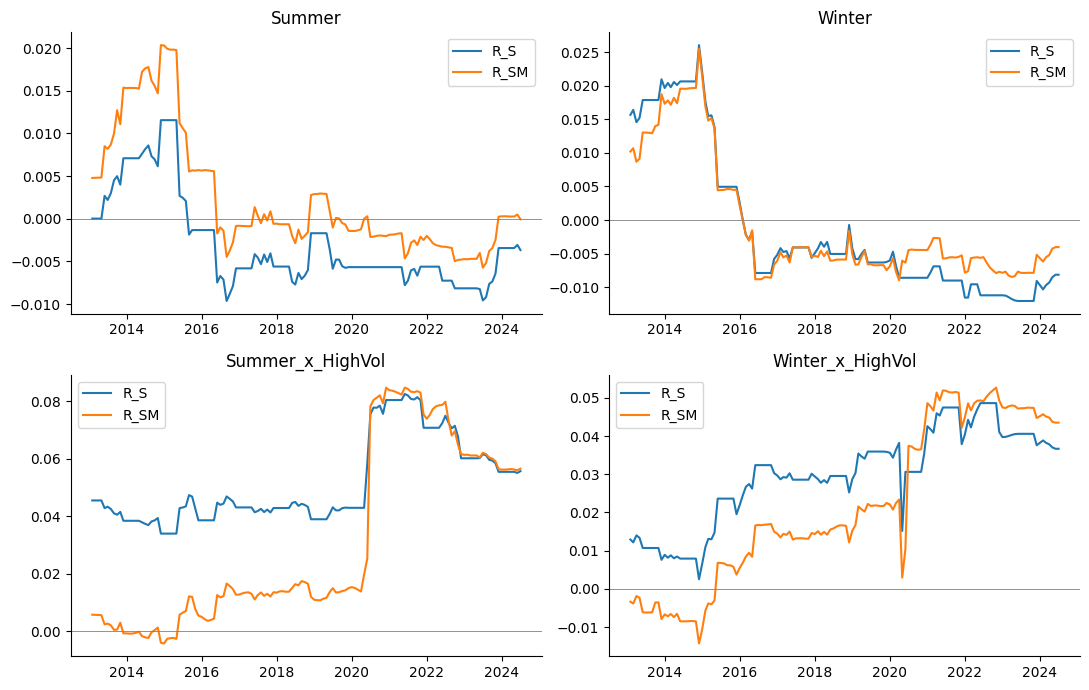

In [13]:
train=d.loc[:'2012-12-31'];stationarity=[]
for col in [Y]+BASE:
 with warnings.catch_warnings():
  warnings.simplefilter('ignore');ad=adfuller(train[col],autolag='AIC');kp=kpss(train[col],regression='c',nlags='auto')
 stationarity.append([col,ad[1],kp[1]])
display(pd.DataFrame(stationarity,columns=['Variable','ADF_p','KPSS_p_bound']))
diag=[];wald=[];coef_tables=[]
for model in ['R_S','R_SM']:
 x=design(train,SPECS[model]);fit=sm.OLS(train[Y],x).fit()
 values={'BG3':acorr_breusch_godfrey(fit,nlags=3)[1],'BG12':acorr_breusch_godfrey(fit,nlags=12)[1],'BP':het_breuschpagan(fit.resid,x)[1],'ARCH3':het_arch(fit.resid,nlags=3)[1],'CUSUM':breaks_cusumolsresid(fit.resid,ddof=x.shape[1])[1]}
 for name,val in values.items():diag.append([model,name,val])
 for lag in [3,6]:
  f=sm.OLS(train[Y],x).fit(cov_type='HAC',cov_kwds={'maxlags':lag})
  if lag==3:coef_tables.append(pd.DataFrame({'Model':model,'Coefficient':f.params,'HAC_SE':f.bse,'p':f.pvalues}))
  for label,r in [('Interactions','Summer_x_HighVol=0, Winter_x_HighVol=0'),('High-state seasonal effects','Summer+Summer_x_HighVol=0, Winter+Winter_x_HighVol=0')]:
   w=f.wald_test(r,scalar=True);wald.append([model,lag,label,float(w.pvalue)])
diagnostics=pd.DataFrame(diag,columns=['Model','Test','p']);season_tests=pd.DataFrame(wald,columns=['Model','HAC','Hypothesis','p'])
display(pd.concat(coef_tables));display(diagnostics.pivot(index='Test',columns='Model',values='p'));display(season_tests)
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,term in zip(axes.flat,['Summer','Winter','Summer_x_HighVol','Winter_x_HighVol']):
 for model in ['R_S','R_SM']:
  z=coef.loc[coef.Model==model];ax.plot(z.Date,z[term],label=model)
 ax.axhline(0,color='grey',lw=.6);ax.set_title(term);ax.legend()
plt.tight_layout();plt.show()


## Trading assessment
The following summary uses the same sample, target, state and position rule for both models. Forecast skill relative to the mean and the incremental R_SM-versus-R_S test determine whether complexity adds information. Trading returns describe the economic consequences under the stated assumptions; 2024 annual returns cover only January–June.

In [14]:
summary=accuracy.query("Model in ['R_S','R_SM']")[['State','Model','RMSE','MAE','R2_mean','Direction']]
display(summary);display(main.query("Model in ['R_S','R_SM']"))

bundles['R']={key:globals()[key].copy() for key in ['accuracy','tests','trading','robust','diagnostics','season_tests','coef','p','main']}


,State,Model,RMSE,MAE,R2_mean,Direction
4,All,R_S,0.12246,0.08341,-0.02425,0.46377
5,All,R_SM,0.13680,0.08990,-0.27813,0.42754
12,High,R_S,0.22207,0.15032,-0.01901,0.41667
13,High,R_SM,0.25963,0.16689,-0.39288,0.37500
20,Low,R_S,0.08816,0.06933,-0.03133,0.47368
21,Low,R_SM,0.09200,0.07369,-0.12299,0.43860


,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover
0,R_S,-0.06503,0.30429,-0.08073,-0.82686,0.74638,26.00000
1,R_SM,-0.06100,0.20258,-0.20609,-0.79399,0.56522,54.00000


## Four-model comparison

,Target,State,Model,N,RMSE,MAE,R2_mean,Direction
4,P,All,P_S,138,0.12659,0.08366,-0.02710,0.48551
5,P,All,P_SM,138,0.13715,0.09129,-0.20546,0.46377
12,P,High,P_S,24,0.23140,0.14890,-0.02268,0.37500
13,P,High,P_SM,24,0.25522,0.16570,-0.24407,0.41667
20,P,Low,P_S,114,0.09015,0.06992,-0.03329,0.50877
21,P,Low,P_SM,114,0.09516,0.07562,-0.15136,0.47368
28,R,All,R_S,138,0.12246,0.08341,-0.02425,0.46377
29,R,All,R_SM,138,0.13680,0.08990,-0.27813,0.42754
36,R,High,R_S,24,0.22207,0.15032,-0.01901,0.41667
37,R,High,R_SM,24,0.25963,0.16689,-0.39288,0.37500


,Model,CAGR,Volatility,Sharpe,MaxDD,Exposure,Turnover,Target
0,P_S,-0.09177,0.40902,-0.03876,-0.87679,0.89855,22.00000,P
1,P_SM,-0.04048,0.22580,-0.06924,-0.71711,0.64493,42.00000,P
4,R_S,-0.06503,0.30429,-0.08073,-0.82686,0.74638,26.00000,R
5,R_SM,-0.06100,0.20258,-0.20609,-0.79399,0.56522,54.00000,R


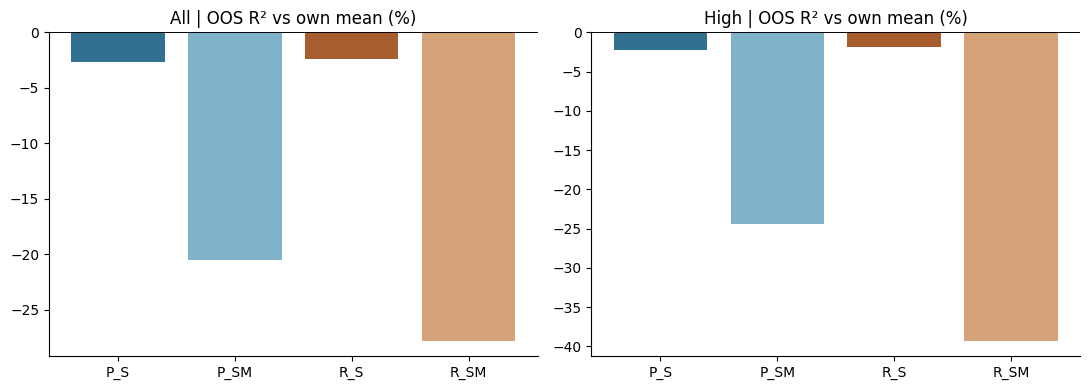

In [15]:
all_accuracy=pd.concat([b['accuracy'].assign(Target=k) for k,b in bundles.items()],ignore_index=True)
all_trading=pd.concat([b['main'].assign(Target=k) for k,b in bundles.items()],ignore_index=True)
all_tests=pd.concat([b['tests'].assign(Target=k) for k,b in bundles.items()],ignore_index=True)
models=['P_S','P_SM','R_S','R_SM']
display(all_accuracy.query('Model in @models')[['Target','State','Model','N','RMSE','MAE','R2_mean','Direction']])
display(all_trading.query('Model in @models'))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,state in zip(axes,['All','High']):
 z=all_accuracy.query('Model in @models and State==@state').set_index('Model')
 ax.bar(z.index,z.R2_mean*100,color=['#31708e','#80b2c9','#a65e2e','#d6a378'])
 ax.axhline(0,color='black',lw=.7);ax.set_title(state+' | OOS R² vs own mean (%)')
plt.tight_layout();plt.show()
EXPORT=False
if EXPORT:
 out=Path('four_model_results');out.mkdir(exist_ok=True)
 for target,bundle in bundles.items():
  for key,table in bundle.items():table.to_csv(out/f'{target}_{key}.csv',index=True)


**Benchmark definitions:** Mean = expanding historical average; Zero = zero forecast. State uses intercept + H; Season adds S and W; MacroState adds X to State; MacroSeason adds X to Season. All coefficients are estimated on observations preceding the forecast month. Benchmarks share the panel’s target.

**Inference:** ADF and KPSS diagnose stationarity assumptions; they cannot prove economic usefulness. HAC addresses standard-error estimation, not poor forecasts or data-release timing. Only 24 high-state test months are available, limiting precision. Bootstrap intervals are pointwise and conditional on the existing forecasts; the model/scenario comparisons are exploratory rather than multiple-testing-adjusted discoveries.